# Neural Networks from Scratch — A Hands-On Notebook

**Who this is for:** high school students who know a bit of algebra and a bit of Python.
No prior machine learning experience needed.

### The plan

We build up in six steps. Every step is small, and every step is something you can run and play with.

| Part | What we build | Big idea |
|---|---|---|
| 1 | A single neuron that fits a straight line | Loss + gradient descent |
| 2 | A neuron that makes yes/no decisions | Activation functions, classification |
| 3 | A tiny 2-layer network, written by hand | **Backpropagation** (the chain rule) |
| 4 | A real network in pure NumPy | Softmax, mini-batches, MNIST digits |
| 5 | The same network in PyTorch | Autograd does the calculus for you |
| 6 | A convolutional network on Fashion-MNIST | Real task, real accuracy |

### The math you need

Only three things, and we review each one when it shows up:

1. **A line:** $y = wx + b$
2. **A derivative:** how fast something changes. If $L = w^2$, then $\dfrac{dL}{dw} = 2w$.
3. **The chain rule:** if $L$ depends on $y$, and $y$ depends on $w$, then
   $\dfrac{dL}{dw} = \dfrac{dL}{dy}\cdot\dfrac{dy}{dw}$.

That's it. Everything else in this notebook is those three ideas, repeated.

### How to use this notebook

- Run cells **in order** (`Shift + Enter`).
- Look for **🔧 Your turn** boxes — these are small experiments. Change a number, re-run, see what breaks. Breaking things is how you learn what each number does.
- Solutions to the exercises are at the very end.

## Part 0 — Setup

Run this cell first. If a package is missing, install it with `pip install numpy matplotlib torch`
(Google Colab already has all of them).

In [71]:
import numpy as np
import matplotlib.pyplot as plt

# Make results reproducible: the same "random" numbers every time we run.
np.random.seed(0)

# A few plotting defaults so the pictures look nice.
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("NumPy version:", np.__version__)
print("Setup OK. Let's go.")

NumPy version: 2.4.6
Setup OK. Let's go.


---
# Part 1 — A neuron is just a line (that learns)

### The problem

You collected data from students in your school: how many hours they studied for a test,
and what score they got.

You want a rule that turns *hours* into a *predicted score*, so that next time someone tells
you "I studied 5.5 hours" you can guess their score.

The simplest possible rule is a straight line:

$$\hat{y} = w \cdot x + b$$

- $x$ = hours studied (the **input**)
- $\hat{y}$ = predicted score (the "hat" means *prediction*, not the truth)
- $w$ = **weight** — how much one extra hour is worth
- $b$ = **bias** — the score you'd predict for someone who studied 0 hours

**This is already a neural network.** It is a network with exactly one neuron. Everything
we do for the rest of the notebook is stacking many copies of this and letting a computer
choose $w$ and $b$.

In [72]:
import sys
!{sys.executable} -m pip install --force-reinstall matplotlib

zsh:1: no such file or directory: /Users/aayushhegde/Documents/ALL


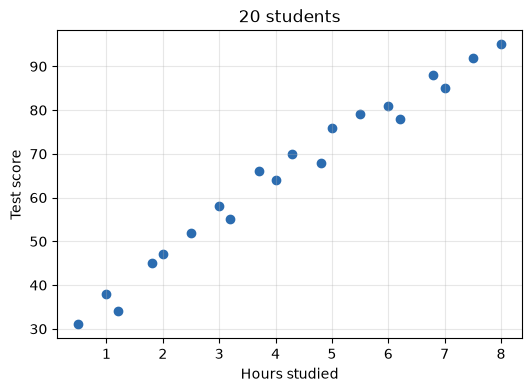

Number of data points: 20


In [73]:
# Our (made-up but realistic) data: 20 students.
hours = np.array([0.5, 1.0, 1.2, 1.8, 2.0, 2.5, 3.0, 3.2, 3.7, 4.0,
                  4.3, 4.8, 5.0, 5.5, 6.0, 6.2, 6.8, 7.0, 7.5, 8.0])
scores = np.array([31, 38, 34, 45, 47, 52, 58, 55, 66, 64,
                   70, 68, 76, 79, 81, 78, 88, 85, 92, 95])

plt.scatter(hours, scores, color="#2b6cb0")
plt.xlabel("Hours studied")
plt.ylabel("Test score")
plt.title("20 students")
plt.show()

print("Number of data points:", len(hours))

### 1.1 Guessing the line by hand

Let's try some values of $w$ and $b$ ourselves. Which line looks best?

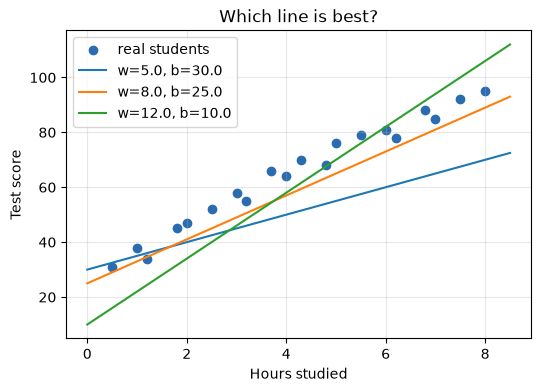

In [74]:
def predict(x, w, b):
    # Our whole model. One line of math.
    return w * x + b

# Three guesses: (w, b)
guesses = [(5.0, 30.0), (8.0, 25.0), (12.0, 10.0)]

x_line = np.linspace(0, 8.5, 100)
plt.scatter(hours, scores, color="#2b6cb0", label="real students")
for w, b in guesses:
    plt.plot(x_line, predict(x_line, w, b), label=f"w={w}, b={b}")
plt.xlabel("Hours studied"); plt.ylabel("Test score")
plt.legend(); plt.title("Which line is best?")
plt.show()

"Which one looks best" is not good enough — a computer can't *look*.
We need a **number** that says how bad a line is. That number is called the **loss**.

### 1.2 The loss function

For one student, the error is $\hat{y}_i - y_i$ (prediction minus truth).
Some errors are positive and some are negative, so if we just added them up they would cancel out.
We square them instead, and take the average. This is the **Mean Squared Error**:

$$L(w, b) = \frac{1}{n}\sum_{i=1}^{n}\left(\hat{y}_i - y_i\right)^2
          = \frac{1}{n}\sum_{i=1}^{n}\left(w x_i + b - y_i\right)^2$$

Small $L$ = good line. Our whole goal is now precise:

> **Find the $w$ and $b$ that make $L$ as small as possible.**

In [75]:
def mse_loss(x, y, w, b):
    y_hat = predict(x, w, b)
    errors = y_hat - y
    return np.mean(errors ** 2)

for w, b in guesses:
    print(f"w={w:5}, b={b:5}  ->  loss = {mse_loss(hours, scores, w, b):8.2f}")

w=  5.0, b= 30.0  ->  loss =   265.77
w=  8.0, b= 25.0  ->  loss =    51.50
w= 12.0, b= 10.0  ->  loss =    93.02


### 1.3 Looking at the loss

Let's freeze $b = 25$ and plot the loss for many different values of $w$.

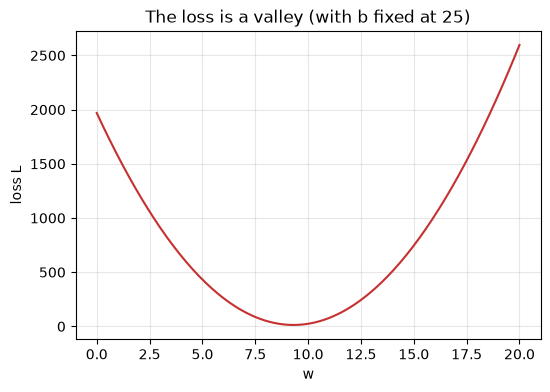

Lowest point of the curve is near w = 9.35


In [76]:
w_values = np.linspace(0, 20, 200)
losses = [mse_loss(hours, scores, w, 25.0) for w in w_values]

plt.plot(w_values, losses, color="#c53030")
plt.xlabel("w"); plt.ylabel("loss L")
plt.title("The loss is a valley (with b fixed at 25)")
plt.show()

best_w = w_values[int(np.argmin(losses))]
print("Lowest point of the curve is near w =", round(best_w, 2))

The loss is a **valley**. We want to get to the bottom.

Imagine you're standing on that curve, blindfolded. You can't see the bottom,
but you *can* feel which way the ground slopes under your feet. So you take a small step
downhill, and repeat. That is the entire algorithm.

The slope is the **derivative**. This algorithm is **gradient descent**.

### 1.4 The derivative (the only calculus in this notebook)

We need the slope of $L$ with respect to $w$, and with respect to $b$.
Starting from

$$L = \frac{1}{n}\sum_i (w x_i + b - y_i)^2$$

Use the chain rule on each term — the outside function is "square it" (derivative $2u$),
the inside is $u = wx_i + b - y_i$ whose derivative with respect to $w$ is just $x_i$:

$$\boxed{\ \frac{\partial L}{\partial w} = \frac{2}{n}\sum_i (\hat{y}_i - y_i)\, x_i\ }
\qquad
\boxed{\ \frac{\partial L}{\partial b} = \frac{2}{n}\sum_i (\hat{y}_i - y_i)\ }$$

(The symbol $\partial$ is just a $d$ for when there is more than one variable — "the slope in the $w$ direction".)

Notice the pattern, because it will come back in *every* network we build:

> **slope = (how wrong we were) × (the input that caused it)**

### 1.5 The update rule

Once we know the slope, we step **downhill** — the opposite direction of the slope:

$$w \leftarrow w - \alpha \frac{\partial L}{\partial w}
\qquad
b \leftarrow b - \alpha \frac{\partial L}{\partial b}$$

$\alpha$ (alpha) is the **learning rate**: the size of our step. It is the single most important
number you will ever tune. Too small and you crawl; too big and you leap over the valley and fly off.

In [77]:
def gradients(x, y, w, b):
    # Return dL/dw and dL/db for the mean-squared-error loss.
    n = len(x)
    y_hat = predict(x, w, b)
    error = y_hat - y                 # how wrong we were, for each student
    dw = (2 / n) * np.sum(error * x)  # wrongness x input
    db = (2 / n) * np.sum(error)      # wrongness (the input for b is always 1)
    return dw, db


def train_line(x, y, w=0.0, b=0.0, lr=0.01, steps=2000, verbose=True):
    history = []
    for step in range(steps):
        dw, db = gradients(x, y, w, b)
        w = w - lr * dw     # <- gradient descent, right here
        b = b - lr * db
        loss = mse_loss(x, y, w, b)
        history.append((w, b, loss))
        if verbose and step % 400 == 0:
            print(f"step {step:4d}  w={w:6.3f}  b={b:6.3f}  loss={loss:8.2f}")
    return w, b, history


w_final, b_final, history = train_line(hours, scores, lr=0.01, steps=2000)
print(f"\nLearned rule:  score = {w_final:.2f} x hours + {b_final:.2f}")

step    0  w= 6.304  b= 1.302  loss= 1423.67
step  400  w= 9.370  b=24.699  loss=   13.64
step  800  w= 8.613  b=28.736  loss=    8.46
step 1200  w= 8.474  b=29.475  loss=    8.29
step 1600  w= 8.448  b=29.610  loss=    8.28

Learned rule:  score = 8.44 x hours + 29.63


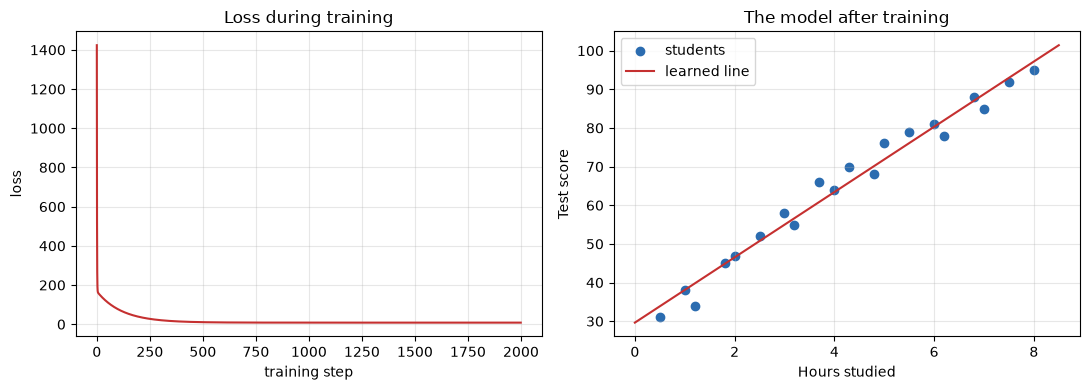

If you study 5.5 hours, the model predicts a score of 76.1


In [78]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Left: the loss going down over time
ax[0].plot([h[2] for h in history], color="#c53030")
ax[0].set_xlabel("training step"); ax[0].set_ylabel("loss")
ax[0].set_title("Loss during training")

# Right: the line we learned
ax[1].scatter(hours, scores, color="#2b6cb0", label="students")
ax[1].plot(x_line, predict(x_line, w_final, b_final), color="#c53030", label="learned line")
ax[1].set_xlabel("Hours studied"); ax[1].set_ylabel("Test score")
ax[1].legend(); ax[1].set_title("The model after training")
plt.tight_layout(); plt.show()

print(f"If you study 5.5 hours, the model predicts a score of {predict(5.5, w_final, b_final):.1f}")

Nobody told the computer what the line was. It started at $w=0, b=0$ (a flat line at zero,
the worst possible guess) and *found* the answer by repeatedly asking "which way is downhill?".

That is what "learning" means in machine learning. There is no magic in the rest of this notebook —
only more neurons.

### 🔧 Your turn #1

Run the cell below with different learning rates. Try `0.001`, `0.01`, `0.03`, `0.05`.

- What happens when `lr` is very small — does 2000 steps get you to the bottom?
- What happens when `lr = 0.05`? (Look for `inf` or `nan`, and an "overflow" warning.
  Each step overshoots the valley and lands further up the other side. You have flown off the mountain.)

lr=0.01: after 10000 steps -> w=8.443, b=29.640, loss=8.284


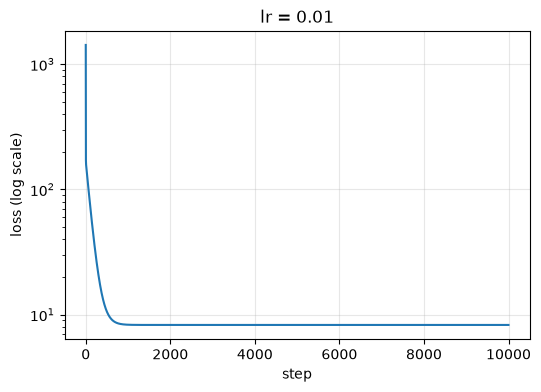

In [79]:
lr = 0.01          # <-- CHANGE ME
steps = 10000       # <-- and maybe me

w_t, b_t, hist = train_line(hours, scores, lr=lr, steps=steps, verbose=False)
final_loss = hist[-1][2]
print(f"lr={lr}: after {steps} steps -> w={w_t:.3f}, b={b_t:.3f}, loss={final_loss:.3f}")

plt.plot([h[2] for h in hist])
plt.yscale("log")   # log scale so we can see both huge and tiny losses
plt.xlabel("step"); plt.ylabel("loss (log scale)"); plt.title(f"lr = {lr}")
plt.show()

---
# Part 2 — A neuron that makes decisions

Predicting a number is called **regression**. But most interesting questions are yes/no:

- Is this email spam?
- Is this X-ray showing pneumonia?
- Is this a picture of a cat?

That is **classification**. Our neuron needs one small upgrade to do it.

### 2.1 The problem

Two features per student: hours studied and hours slept. The label is
$y = 1$ (passed) or $y = 0$ (failed).

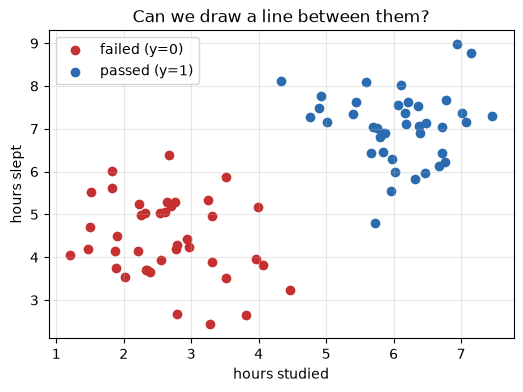

X shape: (80, 2)  y shape: (80,)


In [80]:
np.random.seed(1)

# Group 0: studied little, slept little -> failed
fail = np.random.randn(40, 2) * 0.9 + np.array([2.5, 4.5])
# Group 1: studied more, slept more -> passed
pass_ = np.random.randn(40, 2) * 0.9 + np.array([6.0, 7.0])

X = np.vstack([fail, pass_])            # shape (80, 2): 80 students, 2 features each
y = np.hstack([np.zeros(40), np.ones(40)])   # shape (80,)

plt.scatter(X[y == 0, 0], X[y == 0, 1], color="#c53030", label="failed (y=0)")
plt.scatter(X[y == 1, 0], X[y == 1, 1], color="#2b6cb0", label="passed (y=1)")
plt.xlabel("hours studied"); plt.ylabel("hours slept")
plt.legend(); plt.title("Can we draw a line between them?")
plt.show()

print("X shape:", X.shape, " y shape:", y.shape)

### 2.2 Squashing the output: the sigmoid

Our neuron still computes a weighted sum, but now with two inputs:

$$z = w_1 x_1 + w_2 x_2 + b$$

The problem: $z$ can be $-500$ or $+2000$, and "passed" should be a probability between 0 and 1.
So we squash $z$ through the **sigmoid** function:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

- Very negative $z$ → $\sigma(z) \approx 0$ ("definitely failed")
- $z = 0$ → $\sigma(z) = 0.5$ ("no idea")
- Very positive $z$ → $\sigma(z) \approx 1$ ("definitely passed")

The sigmoid is our first **activation function**. An activation function is a bend applied
to the neuron's output — and, as we'll see in Part 3, bends are what make networks powerful.

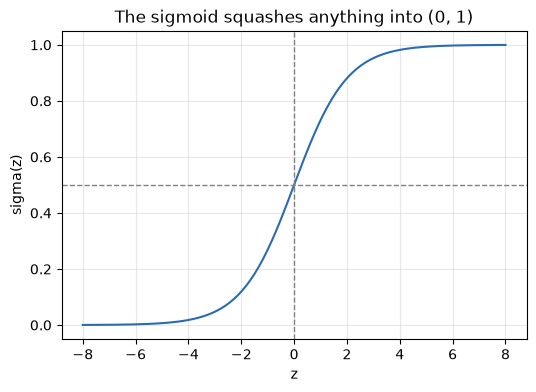

sigma( -6) = 0.0025
sigma( -1) = 0.2689
sigma(  0) = 0.5000
sigma(  1) = 0.7311
sigma(  6) = 0.9975


In [81]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

zs = np.linspace(-8, 8, 200)
plt.plot(zs, sigmoid(zs), color="#2b6cb0")
plt.axhline(0.5, color="gray", ls="--", lw=1)
plt.axvline(0, color="gray", ls="--", lw=1)
plt.xlabel("z"); plt.ylabel("sigma(z)")
plt.title("The sigmoid squashes anything into (0, 1)")
plt.show()

for z in [-6, -1, 0, 1, 6]:
    print(f"sigma({z:3}) = {sigmoid(z):.4f}")

### 2.3 A loss for probabilities

For yes/no answers, mean squared error is a poor choice (it gives almost no gradient when
the model is confidently wrong). The right loss is **binary cross-entropy**, also called log loss:

$$L = -\frac{1}{n}\sum_i \Big[\, y_i \log \hat{y}_i + (1 - y_i)\log(1 - \hat{y}_i)\,\Big]$$

It looks scary; it isn't. Only one of the two terms is ever alive:

- If the true label is $y_i = 1$, the loss for that student is $-\log \hat y_i$.
  Predict 0.99 → loss 0.01 (tiny). Predict 0.01 → loss 4.6 (huge).
- If the true label is $y_i = 0$, the loss is $-\log(1 - \hat y_i)$, which is the mirror image.

In words: **being confidently wrong is punished enormously.**

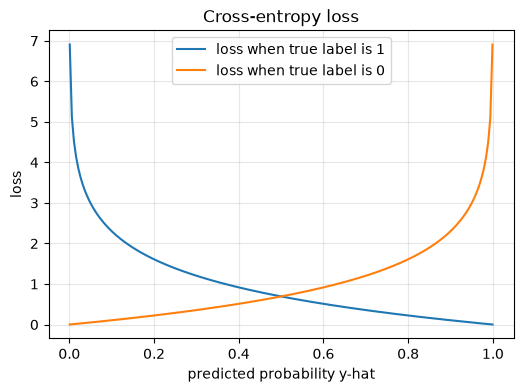

In [82]:
p = np.linspace(0.001, 0.999, 200)
plt.plot(p, -np.log(p), label="loss when true label is 1")
plt.plot(p, -np.log(1 - p), label="loss when true label is 0")
plt.xlabel("predicted probability y-hat"); plt.ylabel("loss")
plt.legend(); plt.title("Cross-entropy loss")
plt.show()

### 2.4 The gradient — a small miracle

We now need $\partial L/\partial w$. There are two links in the chain:
$w \rightarrow z \rightarrow \hat{y} \rightarrow L$. So

$$\frac{\partial L}{\partial w_j} = \frac{\partial L}{\partial \hat y}\cdot\frac{\partial \hat y}{\partial z}\cdot\frac{\partial z}{\partial w_j}$$

The three pieces are:

$$\frac{\partial L}{\partial \hat y} = \frac{\hat y - y}{\hat y (1-\hat y)}, \qquad
\frac{\partial \hat y}{\partial z} = \hat y (1 - \hat y), \qquad
\frac{\partial z}{\partial w_j} = x_j$$

(The middle one is a nice property of the sigmoid: $\sigma'(z) = \sigma(z)\,(1-\sigma(z))$.)

Multiply them, and the ugly middle terms cancel perfectly:

$$\boxed{\ \frac{\partial L}{\partial w_j} = (\hat y - y)\, x_j\ }$$

Exactly the same shape as Part 1: **(how wrong we were) × (the input)**. This is not a coincidence —
cross-entropy and sigmoid were *designed* to fit together this way.

In [83]:
def train_neuron(X, y, lr=0.1, steps=2000):
    n_features = X.shape[1]
    w = np.zeros(n_features)     # one weight per feature
    b = 0.0
    losses = []

    for step in range(steps):
        # ---- forward pass: data -> prediction ----
        z = X @ w + b                 # "@" is matrix multiplication
        y_hat = sigmoid(z)

        # ---- loss ----
        eps = 1e-9                    # keeps log(0) from exploding
        loss = -np.mean(y * np.log(y_hat + eps) + (1 - y) * np.log(1 - y_hat + eps))
        losses.append(loss)

        # ---- backward pass: how should w and b change? ----
        error = y_hat - y             # (n,)
        dw = X.T @ error / len(y)     # (2,)  <- (wrongness) x (input), averaged
        db = np.mean(error)

        # ---- update ----
        w -= lr * dw
        b -= lr * db

    return w, b, losses


w2, b2, losses2 = train_neuron(X, y, lr=0.1, steps=2000)
print("learned weights:", np.round(w2, 3), " bias:", round(b2, 3))

accuracy = np.mean((sigmoid(X @ w2 + b2) > 0.5) == y)
print(f"training accuracy: {accuracy * 100:.1f}%")

learned weights: [1.484 0.303]  bias: -7.978
training accuracy: 100.0%


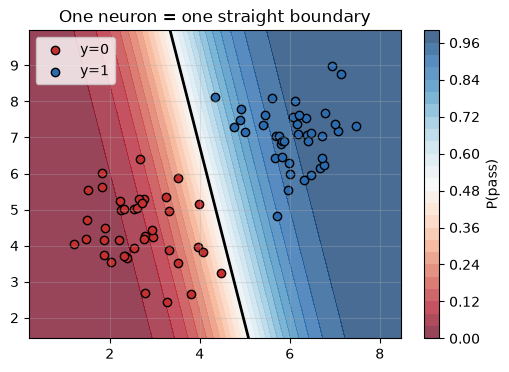

In [84]:
def plot_decision_boundary(predict_proba, X, y, title=""):
    # Colour every point of the plane by what the model would predict there.
    pad = 1.0
    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300),
        np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300),
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    probs = predict_proba(grid).reshape(xx.shape)

    plt.contourf(xx, yy, probs, levels=25, cmap="RdBu", alpha=0.75)
    plt.colorbar(label="P(pass)")
    plt.contour(xx, yy, probs, levels=[0.5], colors="black", linewidths=2)
    plt.scatter(X[y == 0, 0], X[y == 0, 1], color="#c53030", edgecolor="k", label="y=0")
    plt.scatter(X[y == 1, 0], X[y == 1, 1], color="#2b6cb0", edgecolor="k", label="y=1")
    plt.legend(); plt.title(title)
    plt.show()

plot_decision_boundary(lambda g: sigmoid(g @ w2 + b2), X, y,
                       "One neuron = one straight boundary")

The black line is the model's decision boundary, and the colours show how confident it is.
One neuron draws **one straight line**. For this data, that's plenty.

### 2.5 Where one neuron fails: XOR

Here is a dataset that looks harmless and destroys our single neuron.
Class 1 sits in two opposite corners; class 0 in the other two.

Try to draw *one straight line* that separates the blue points from the red ones. You can't.
It is impossible — and no amount of training will fix it.

Single neuron on XOR -> accuracy 50.0%  (coin flipping is 50%)


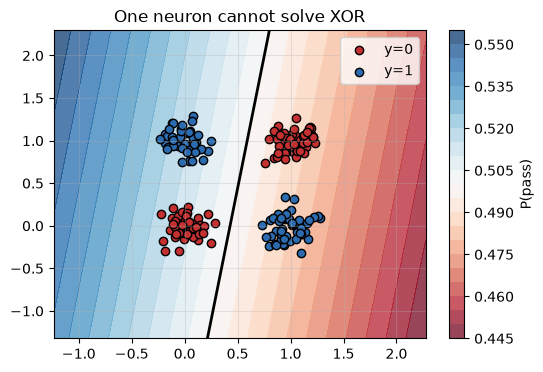

In [85]:
X_xor = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_xor = np.array([0., 1., 1., 0.])          # "exactly one of the two inputs is 1"

# Add a small cloud of points around each corner so the picture is easier to read.
rng = np.random.default_rng(2)
X_xor_big = np.repeat(X_xor, 50, axis=0) + rng.normal(0, 0.12, size=(200, 2))
y_xor_big = np.repeat(y_xor, 50)

w3, b3, _ = train_neuron(X_xor_big, y_xor_big, lr=0.5, steps=5000)
acc = np.mean((sigmoid(X_xor_big @ w3 + b3) > 0.5) == y_xor_big)
print(f"Single neuron on XOR -> accuracy {acc * 100:.1f}%  (coin flipping is 50%)")

plot_decision_boundary(lambda g: sigmoid(g @ w3 + b3), X_xor_big, y_xor_big,
                       "One neuron cannot solve XOR")

This exact problem stopped AI research for over a decade (Minsky & Papert pointed it out in 1969,
and funding for neural networks dried up until the 1980s).

The fix is to **stack neurons in layers** — and the reason it took so long is that nobody knew
how to compute the gradients for a stack. That algorithm is backpropagation, and it is Part 3.

---
# Part 3 — Stacking neurons: the 2-layer network and backpropagation

### 3.1 The idea

One neuron draws one straight line. So let's use **several** neurons, and then a final neuron
that combines their answers.

```
                 ┌─ neuron 1 ─┐
   inputs  x  ───┼─ neuron 2 ─┼───►  output neuron  ───►  y-hat
                 └─ neuron 3 ─┘
                  hidden layer
```

The middle neurons are the **hidden layer** (hidden because we never look at their answers directly —
they are the network's private scratch paper).

**Critical detail:** the hidden neurons *must* have a non-linear activation. If they were plain
lines, then a line of a line is still a line, and the whole network would collapse back into
a single straight boundary. The bend is the point.

$$\underbrace{W_2(W_1 x + b_1) + b_2}_{\text{no activation: still one line}}
\qquad \text{vs.} \qquad
\underbrace{W_2\,\tanh(W_1 x + b_1) + b_2}_{\text{can bend}}$$

### 3.2 Writing the whole layer in one line of math

Doing neurons one at a time would be slow. Instead we put all the weights of a layer into a
**matrix** and compute all the neurons at once:

$$Z_1 = X W_1 + b_1 \qquad A_1 = \tanh(Z_1) \qquad Z_2 = A_1 W_2 + b_2 \qquad \hat{Y} = \sigma(Z_2)$$

Keeping the shapes straight is 90% of debugging a neural network, so here they are for a batch
of $n$ examples, 2 inputs and $h$ hidden neurons:

| Thing | Shape | Meaning |
|---|---|---|
| $X$ | $(n, 2)$ | the batch of inputs |
| $W_1$ | $(2, h)$ | input → hidden weights |
| $b_1$ | $(h,)$ | one bias per hidden neuron |
| $Z_1, A_1$ | $(n, h)$ | what each hidden neuron says about each example |
| $W_2$ | $(h, 1)$ | hidden → output weights |
| $\hat{Y}$ | $(n, 1)$ | one probability per example |

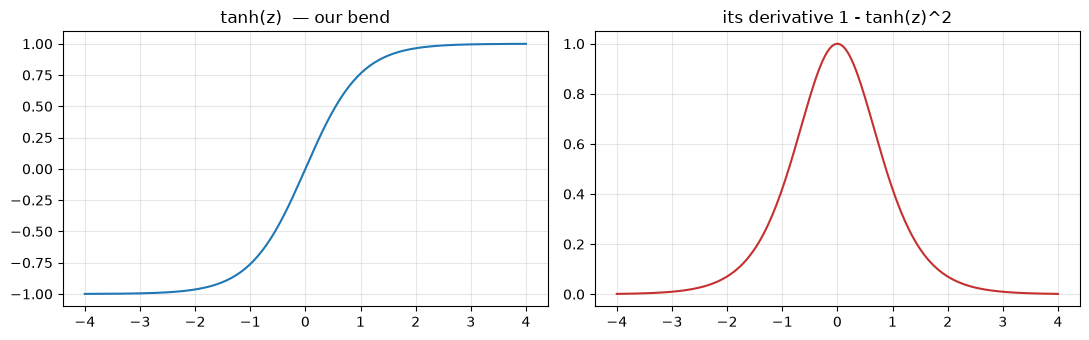

In [86]:
def tanh(z):
    return np.tanh(z)

def tanh_derivative(a):
    # If a = tanh(z), then d(tanh)/dz = 1 - a^2.  Handy: we reuse the output.
    return 1 - a ** 2

zs = np.linspace(-4, 4, 200)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(zs, tanh(zs)); ax[0].set_title("tanh(z)  — our bend")
ax[1].plot(zs, tanh_derivative(tanh(zs)), color="#c53030")
ax[1].set_title("its derivative 1 - tanh(z)^2")
plt.tight_layout(); plt.show()

### 3.3 The chain rule, concretely

Backpropagation is the chain rule applied backwards through the network. Before we use it on a
network, let's make sure it feels obvious on a tiny example.

Suppose $u = 3w$, $v = u^2$, and $L = v + 5$. What is $\dfrac{dL}{dw}$ when $w = 2$?

$$\frac{dL}{dw} = \frac{dL}{dv}\cdot\frac{dv}{du}\cdot\frac{du}{dw} = 1 \cdot 2u \cdot 3 = 6u = 6(3w) = 18w = 36$$

We can check this numerically: nudge $w$ by a tiny amount $\varepsilon$ and see how much $L$ moves.

In [87]:
def L_of_w(w):
    u = 3 * w
    v = u ** 2
    return v + 5

w0 = 2.0
eps = 1e-6
numerical = (L_of_w(w0 + eps) - L_of_w(w0 - eps)) / (2 * eps)
analytic = 18 * w0

print(f"numerical slope: {numerical:.6f}")
print(f"chain rule says: {analytic:.6f}")

numerical slope: 36.000000
chain rule says: 36.000000


That trick — comparing hand-derived gradients against a numerical nudge — is called
**gradient checking**, and it is how professionals catch bugs in backpropagation code.
We'll use it on the real network in a minute.

### 3.4 Backpropagation for our 2-layer network

We go **backwards**, layer by layer. Each step asks: "how much does the loss change if this
quantity changes?" We write $\delta$ (delta) for those answers.

**Step 1 — the output layer.** With sigmoid + cross-entropy, we already saw the magic cancellation:

$$\delta_2 = \frac{\partial L}{\partial Z_2} = \frac{1}{n}(\hat{Y} - Y)$$

**Step 2 — gradients for $W_2$, $b_2$.** Same pattern as always, *(wrongness) × (the input to that layer)*,
which for layer 2 is $A_1$:

$$\frac{\partial L}{\partial W_2} = A_1^{\top}\delta_2
\qquad
\frac{\partial L}{\partial b_2} = \sum_{\text{rows}}\delta_2$$

**Step 3 — push the blame back to the hidden layer.** Each hidden neuron is responsible in
proportion to the weight connecting it to the output:

$$\frac{\partial L}{\partial A_1} = \delta_2 W_2^{\top}$$

**Step 4 — through the activation.** Multiply by the derivative of tanh (element by element):

$$\delta_1 = \frac{\partial L}{\partial Z_1} = \left(\delta_2 W_2^{\top}\right) \odot (1 - A_1^2)$$

**Step 5 — gradients for $W_1$, $b_1$.** Same pattern once more, with input $X$:

$$\frac{\partial L}{\partial W_1} = X^{\top}\delta_1
\qquad
\frac{\partial L}{\partial b_1} = \sum_{\text{rows}}\delta_1$$

That's the whole algorithm. Read it once more and notice there are really only **three** moves:

1. multiply by the incoming activations to get a weight gradient,
2. multiply by $W^{\top}$ to send blame to the previous layer,
3. multiply by the activation's derivative to get through the bend.

A 100-layer network uses exactly these three moves, 100 times.

In [88]:
class TwoLayerNet:
    # A neural network with one hidden layer, written out by hand.

    def __init__(self, n_inputs, n_hidden, seed=0):
        rng = np.random.default_rng(seed)
        # Small random starting weights. If we started at all-zeros, every hidden neuron
        # would compute exactly the same thing forever -- they must start different.
        self.W1 = rng.normal(0, 1.0, size=(n_inputs, n_hidden)) * np.sqrt(1 / n_inputs)
        self.b1 = np.zeros(n_hidden)
        self.W2 = rng.normal(0, 1.0, size=(n_hidden, 1)) * np.sqrt(1 / n_hidden)
        self.b2 = np.zeros(1)

    # ---------- forward: data in, prediction out ----------
    def forward(self, X):
        self.X = X
        self.Z1 = X @ self.W1 + self.b1      # (n, h)
        self.A1 = np.tanh(self.Z1)           # (n, h)   the bend
        self.Z2 = self.A1 @ self.W2 + self.b2  # (n, 1)
        self.A2 = sigmoid(self.Z2)           # (n, 1)   probability
        return self.A2

    def loss(self, Y):
        eps = 1e-9
        return -np.mean(Y * np.log(self.A2 + eps) + (1 - Y) * np.log(1 - self.A2 + eps))

    # ---------- backward: the five steps from above ----------
    def backward(self, Y):
        n = len(Y)
        d2 = (self.A2 - Y) / n                      # step 1
        dW2 = self.A1.T @ d2                        # step 2
        db2 = d2.sum(axis=0)
        dA1 = d2 @ self.W2.T                        # step 3
        d1 = dA1 * (1 - self.A1 ** 2)               # step 4  (tanh derivative)
        dW1 = self.X.T @ d1                         # step 5
        db1 = d1.sum(axis=0)
        return dW1, db1, dW2, db2

    def step(self, grads, lr):
        dW1, db1, dW2, db2 = grads
        self.W1 -= lr * dW1
        self.b1 -= lr * db1
        self.W2 -= lr * dW2
        self.b2 -= lr * db2

    def fit(self, X, Y, lr=0.5, epochs=3000, verbose_every=500):
        Y = Y.reshape(-1, 1)
        history = []
        for e in range(epochs):
            self.forward(X)
            loss = self.loss(Y)
            history.append(loss)
            self.step(self.backward(Y), lr)
            if verbose_every and e % verbose_every == 0:
                print(f"epoch {e:5d}   loss {loss:.4f}")
        return history

    def predict_proba(self, X):
        return self.forward(X).ravel()

### 3.5 Gradient check — is our calculus right?

Before trusting the network, we test the backward pass against numerically estimated slopes.
If the two agree to ~6 decimal places, our derivation is correct.

In [89]:
net_check = TwoLayerNet(n_inputs=2, n_hidden=4, seed=3)
Xc = np.random.randn(5, 2)
Yc = np.array([[1.], [0.], [1.], [0.], [1.]])

net_check.forward(Xc)
dW1_analytic = net_check.backward(Yc)[0]

# Numerically wiggle one weight at a time and watch the loss.
eps = 1e-6
dW1_numeric = np.zeros_like(net_check.W1)
for i in range(net_check.W1.shape[0]):
    for j in range(net_check.W1.shape[1]):
        original = net_check.W1[i, j]

        net_check.W1[i, j] = original + eps
        net_check.forward(Xc); loss_plus = net_check.loss(Yc)

        net_check.W1[i, j] = original - eps
        net_check.forward(Xc); loss_minus = net_check.loss(Yc)

        net_check.W1[i, j] = original          # put it back!
        dW1_numeric[i, j] = (loss_plus - loss_minus) / (2 * eps)

print("backprop gradient:\n", np.round(dW1_analytic, 6))
print("\nnumerical gradient:\n", np.round(dW1_numeric, 6))
print("\nlargest disagreement:", np.max(np.abs(dW1_analytic - dW1_numeric)))
print("(anything below 1e-6 means our backpropagation is correct)")

backprop gradient:
 [[ 0.005287 -0.030455 -0.002953  0.05343 ]
 [-0.014044  0.020815  0.002918 -0.050471]]

numerical gradient:
 [[ 0.005287 -0.030455 -0.002953  0.05343 ]
 [-0.014044  0.020815  0.002918 -0.050471]]

largest disagreement: 5.07346900602279e-10
(anything below 1e-6 means our backpropagation is correct)


### 3.6 Revenge on XOR

The problem that one neuron could not solve, with 4 hidden neurons:

epoch     0   loss 0.6860
epoch   500   loss 0.0159
epoch  1000   loss 0.0068
epoch  1500   loss 0.0043
epoch  2000   loss 0.0031
epoch  2500   loss 0.0025

accuracy: 100.0%   (one neuron managed ~50%)


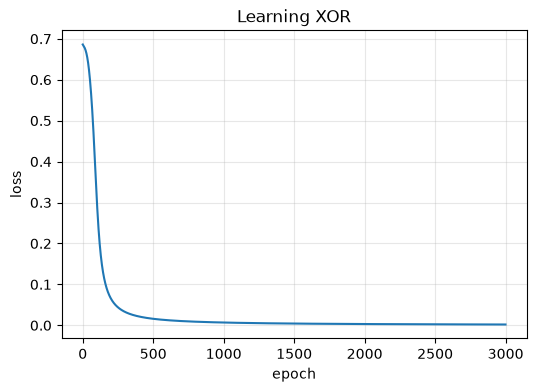

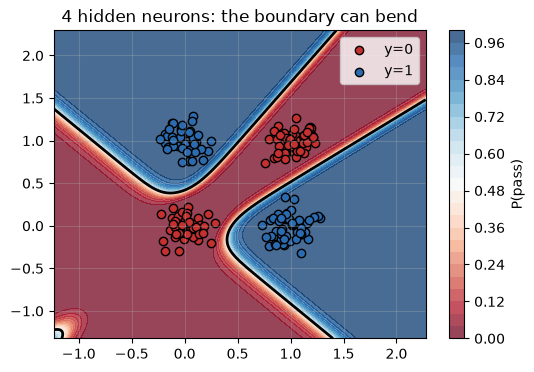

In [90]:
net = TwoLayerNet(n_inputs=2, n_hidden=4, seed=1)
hist = net.fit(X_xor_big, y_xor_big, lr=0.5, epochs=3000, verbose_every=500)

acc = np.mean((net.predict_proba(X_xor_big) > 0.5) == y_xor_big)
print(f"\naccuracy: {acc * 100:.1f}%   (one neuron managed ~50%)")

plt.plot(hist); plt.xlabel("epoch"); plt.ylabel("loss")
plt.title("Learning XOR"); plt.show()

plot_decision_boundary(net.predict_proba, X_xor_big, y_xor_big,
                       "4 hidden neurons: the boundary can bend")

Look at that boundary — it is **curved**, and it wraps around the corners. Four straight
lines, combined by the output neuron, became a curve. That is what depth buys you.

### 3.7 How many hidden neurons?

Let's try a harder, more organic-looking dataset (two interlocking crescent moons) with
different numbers of hidden neurons.

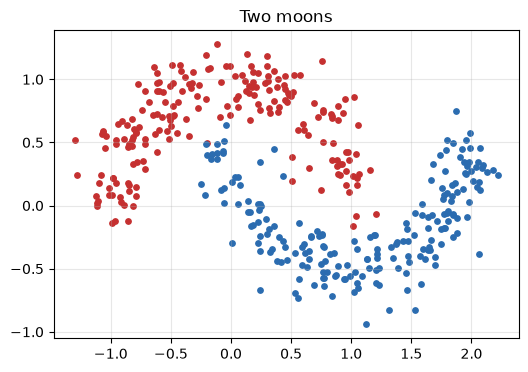

In [91]:
def make_moons(n=400, noise=0.2, seed=0):
    # Two interlocking crescents -- a classic "you need a curved boundary" dataset.
    rng = np.random.default_rng(seed)
    t = rng.uniform(0, np.pi, n // 2)
    outer = np.stack([np.cos(t), np.sin(t)], axis=1)
    inner = np.stack([1 - np.cos(t), 0.5 - np.sin(t)], axis=1)
    X = np.vstack([outer, inner]) + rng.normal(0, noise, size=(n, 2))
    y = np.hstack([np.zeros(n // 2), np.ones(n // 2)])
    return X, y

X_moon, y_moon = make_moons(n=400, noise=0.15, seed=4)

plt.scatter(X_moon[y_moon == 0, 0], X_moon[y_moon == 0, 1], color="#c53030", s=15)
plt.scatter(X_moon[y_moon == 1, 0], X_moon[y_moon == 1, 1], color="#2b6cb0", s=15)
plt.title("Two moons"); plt.show()

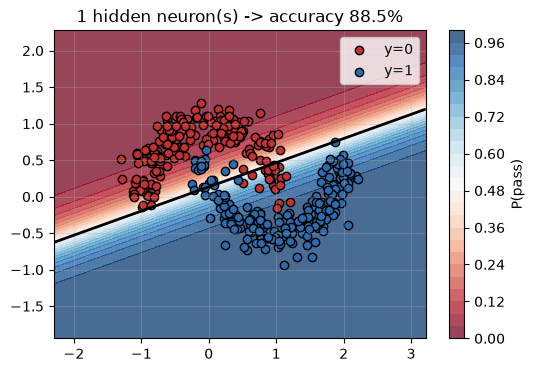

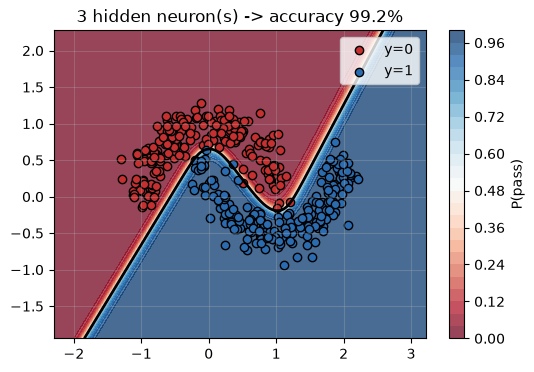

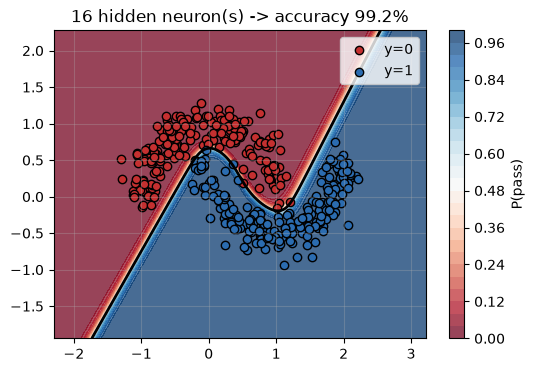

In [92]:
for h in [1, 3, 16]:
    m = TwoLayerNet(n_inputs=2, n_hidden=h, seed=0)
    m.fit(X_moon, y_moon, lr=0.5, epochs=4000, verbose_every=0)
    a = np.mean((m.predict_proba(X_moon) > 0.5) == y_moon)
    plot_decision_boundary(m.predict_proba, X_moon, y_moon,
                           f"{h} hidden neuron(s) -> accuracy {a*100:.1f}%")

- **1 hidden neuron** is basically back to a straight line.
- **3** is enough to bend around the moons.
- **16** gives a boundary that hugs the data more tightly — sometimes *too* tightly. Chasing
  individual noisy points instead of the real pattern is called **overfitting**, and it is
  the main enemy in Part 6.

### 🔧 Your turn #2

In the cell below:

1. Set `HIDDEN = 1` and re-run. Can the network still learn XOR? Why not?
2. Set `ACTIVATION = "identity"` (no bend at all) with `HIDDEN = 16`. What accuracy do you get,
   and what shape is the boundary? This is the "a line of a line is still a line" fact, live.
3. Set `LR = 5.0`. Does it learn faster, or does it break?

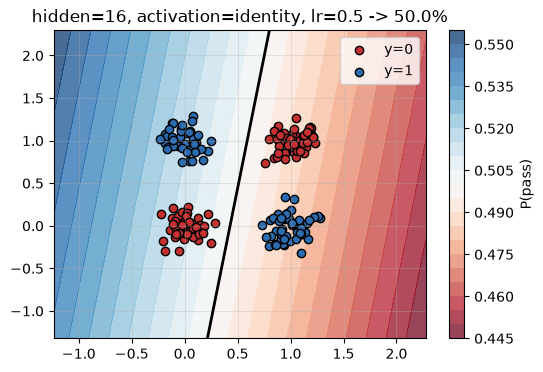

In [93]:
HIDDEN = 16              # <-- try 1, 2, 4, 32
ACTIVATION = "identity"     # <-- try "identity"
LR = 0.5                # <-- try 0.05 or 5.0

class ConfigurableNet(TwoLayerNet):
    def forward(self, X):
        self.X = X
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = np.tanh(self.Z1) if ACTIVATION == "tanh" else self.Z1
        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = sigmoid(self.Z2)
        return self.A2

    def backward(self, Y):
        n = len(Y)
        d2 = (self.A2 - Y) / n
        dW2 = self.A1.T @ d2
        db2 = d2.sum(axis=0)
        dA1 = d2 @ self.W2.T
        # the ONLY difference: the derivative of the activation
        d1 = dA1 * (1 - self.A1 ** 2) if ACTIVATION == "tanh" else dA1
        dW1 = self.X.T @ d1
        db1 = d1.sum(axis=0)
        return dW1, db1, dW2, db2

exp = ConfigurableNet(2, HIDDEN, seed=1)
exp.fit(X_xor_big, y_xor_big, lr=LR, epochs=3000, verbose_every=0)
a = np.mean((exp.predict_proba(X_xor_big) > 0.5) == y_xor_big)
plot_decision_boundary(exp.predict_proba, X_xor_big, y_xor_big,
                       f"hidden={HIDDEN}, activation={ACTIVATION}, lr={LR} -> {a*100:.1f}%")

---
# Part 4 — The real thing: handwritten digits, in pure NumPy

Time to leave toy data. **MNIST** is 70,000 photographs of handwritten digits, each a
28×28 grayscale image, labelled 0–9. It is the "hello world" of deep learning.

We are going to classify them with a network we write ourselves — no deep learning library.
Three upgrades are needed:

1. **Many inputs.** 28×28 = 784 numbers per image. We flatten each image into a vector of 784.
2. **Ten outputs instead of one.** We need a probability for each digit → **softmax**.
3. **Mini-batches.** Using all 60,000 images for every single step is slow. Use 64 at a time.

### 4.1 Getting the data

The next cell downloads MNIST (about 11 MB) the first time you run it and caches it in a
`data/` folder next to this notebook. Later runs are instant.

In [94]:
import gzip, os, urllib.request

DATA_DIR = "data"

FILES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images":  "t10k-images-idx3-ubyte.gz",
    "test_labels":  "t10k-labels-idx1-ubyte.gz",
}

MIRRORS = {
    "mnist": [
        "https://ossci-datasets.s3.amazonaws.com/mnist/",
        "https://raw.githubusercontent.com/fgnt/mnist/master/",
    ],
    "fashion": [
        "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/",
    ],
}


def _download(dataset, filename):
    os.makedirs(DATA_DIR, exist_ok=True)
    path = os.path.join(DATA_DIR, f"{dataset}_{filename}")
    if os.path.exists(path):
        return path
    last_error = None
    for base in MIRRORS[dataset]:
        try:
            print("downloading", base + filename, "...")
            req = urllib.request.Request(base + filename,
                                         headers={"User-Agent": "python-notebook"})
            with urllib.request.urlopen(req, timeout=60) as r, open(path, "wb") as f:
                f.write(r.read())
            return path
        except Exception as e:          # try the next mirror
            last_error = e
    raise RuntimeError(f"Could not download {filename}: {last_error}")


def _read_idx(path):
    # The IDX file format: a small header, then raw bytes.
    with gzip.open(path, "rb") as f:
        data = f.read()
    magic = int.from_bytes(data[:4], "big")
    n_dims = magic % 256
    dims = [int.from_bytes(data[4 + 4 * i: 8 + 4 * i], "big") for i in range(n_dims)]
    return np.frombuffer(data[4 + 4 * n_dims:], dtype=np.uint8).reshape(dims)


def load_dataset(dataset="mnist"):
    # Returns X_train, y_train, X_test, y_test.
    # Images are flattened to 784 numbers and scaled to the range 0..1.
    out = {}
    for key, fname in FILES.items():
        out[key] = _read_idx(_download(dataset, fname))
    X_train = out["train_images"].reshape(-1, 28 * 28).astype(np.float32) / 255.0
    X_test = out["test_images"].reshape(-1, 28 * 28).astype(np.float32) / 255.0
    return X_train, out["train_labels"].astype(np.int64), X_test, out["test_labels"].astype(np.int64)


X_train, y_train, X_test, y_test = load_dataset("mnist")
print("training images:", X_train.shape, " labels:", y_train.shape)
print("test images:    ", X_test.shape)
print("pixel values run from", X_train.min(), "to", X_train.max())

training images: (60000, 784)  labels: (60000,)
test images:     (10000, 784)
pixel values run from 0.0 to 1.0


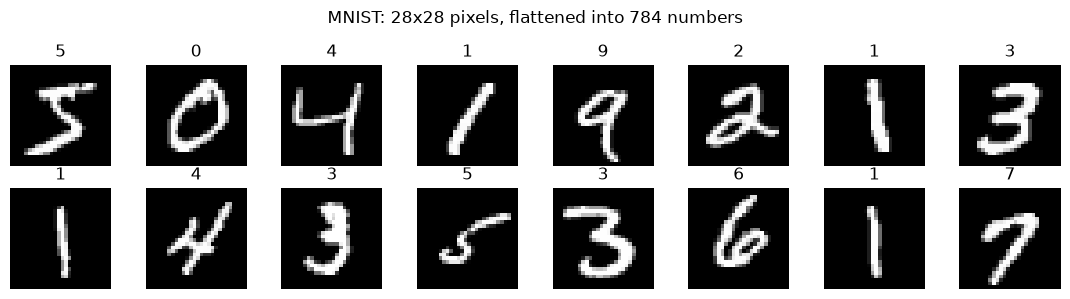

first 40 numbers of image #0:
[0.   0.   0.   0.19 0.93 0.99 0.99 0.99 0.99 0.99 0.99 0.99 0.99 0.98
 0.36 0.32 0.32 0.22 0.15 0.   0.   0.   0.   0.   0.   0.   0.   0.
 0.   0.   0.   0.07 0.86 0.99 0.99 0.99 0.99 0.99 0.78 0.71]


In [95]:
# What does the data actually look like?
fig, axes = plt.subplots(2, 8, figsize=(11, 3))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(int(y_train[i]))
    ax.axis("off"); ax.grid(False)
plt.suptitle("MNIST: 28x28 pixels, flattened into 784 numbers")
plt.tight_layout(); plt.show()

# A single image, as the network sees it: just a list of numbers.
print("first 40 numbers of image #0:")
print(np.round(X_train[0][200:240], 2))

### 4.2 Ten outputs: softmax

For 10 classes, the last layer produces 10 numbers ("scores", or **logits**) — one per digit.
We turn them into probabilities that sum to 1 with the **softmax**:

$$p_k = \frac{e^{z_k}}{\sum_{j=1}^{10} e^{z_j}}$$

Exponentiating makes everything positive and exaggerates differences; dividing by the sum
makes them add to 1.

The loss is cross-entropy again, but now over 10 classes. If the true digit is $c$:

$$L = -\log p_c$$

And — beautifully — the gradient is *still* the same pattern:

$$\frac{\partial L}{\partial Z} = P - Y_{\text{one-hot}}$$

where "one-hot" means the true label written as a vector of 9 zeros and a single 1.
Every single loss/activation pair in this notebook has produced **prediction minus truth**.
That's not luck; it's why these particular functions are the standard choice.

In [96]:
def softmax(Z):
    # Subtracting the max is a numerical safety trick: it prevents exp() from overflowing
    # and changes nothing mathematically (the term cancels top and bottom).
    Z = Z - Z.max(axis=1, keepdims=True)
    e = np.exp(Z)
    return e / e.sum(axis=1, keepdims=True)

def one_hot(y, n_classes=10):
    out = np.zeros((len(y), n_classes))
    out[np.arange(len(y)), y] = 1
    return out

example_scores = np.array([[2.0, 1.0, 0.1, -1.0]])
print("scores:       ", example_scores.ravel())
print("probabilities:", np.round(softmax(example_scores).ravel(), 3), " (they sum to 1)")
print("\nlabel 3 as one-hot:", one_hot(np.array([3]), 10).ravel())

scores:        [ 2.   1.   0.1 -1. ]
probabilities: [0.638 0.235 0.095 0.032]  (they sum to 1)

label 3 as one-hot: [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]


### 4.3 ReLU: the activation everyone actually uses

For deep networks, `tanh` has a problem: its derivative is nearly zero when $|z|$ is large,
so gradients shrink to nothing as they travel backwards ("vanishing gradients").

**ReLU** — Rectified Linear Unit — fixes this by being aggressively simple:

$$\text{ReLU}(z) = \max(0, z) \qquad \text{ReLU}'(z) = \begin{cases}1 & z > 0\\ 0 & z \le 0\end{cases}$$

It's a bend, so it still provides non-linearity, and its derivative is exactly 1 for all
positive inputs, so gradients pass through unharmed. Almost every modern network uses ReLU
or a close relative.

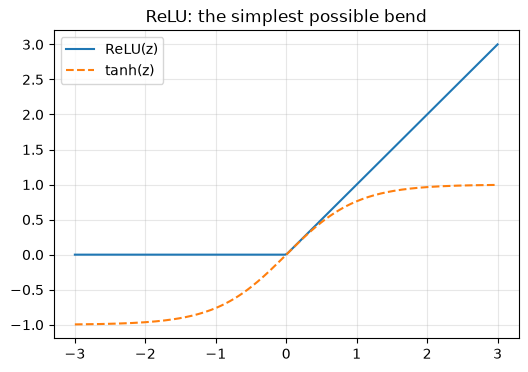

In [97]:
zs = np.linspace(-3, 3, 200)
plt.plot(zs, np.maximum(0, zs), label="ReLU(z)")
plt.plot(zs, np.tanh(zs), label="tanh(z)", ls="--")
plt.legend(); plt.title("ReLU: the simplest possible bend"); plt.show()

### 4.4 The network

Now we generalise `TwoLayerNet` into a network with any number of layers of any size.
The code is barely longer, because backprop is the same three moves repeated.

We also switch from full-batch to **mini-batch** gradient descent: shuffle the data, take 64
examples at a time, and update after each batch. One pass through all the data is an **epoch**.
Mini-batches make each step ~1000× cheaper, and the noise they add actually helps the network
escape bad spots.

In [98]:
class NeuralNetwork:
    # A fully-connected network with ReLU hidden layers and a softmax output.
    # sizes=[784, 128, 10] means: 784 inputs -> 128 hidden -> 10 outputs.

    def __init__(self, sizes, seed=0):
        rng = np.random.default_rng(seed)
        self.sizes = sizes
        self.W, self.b = [], []
        for i in range(len(sizes) - 1):
            # "He initialisation": scaling by sqrt(2/fan_in) keeps the signal from
            # exploding or dying as it passes through many ReLU layers.
            self.W.append(rng.normal(0, np.sqrt(2 / sizes[i]), size=(sizes[i], sizes[i + 1])))
            self.b.append(np.zeros(sizes[i + 1]))

    def forward(self, X):
        self.activations = [X]          # a[0] = input
        self.zs = []
        A = X
        for i in range(len(self.W)):
            Z = A @ self.W[i] + self.b[i]
            self.zs.append(Z)
            # ReLU on every hidden layer; softmax on the last one
            A = softmax(Z) if i == len(self.W) - 1 else np.maximum(0, Z)
            self.activations.append(A)
        return A

    def backward(self, Y_onehot, lr):
        n = len(Y_onehot)
        # ---- the output layer: prediction minus truth, once again ----
        delta = (self.activations[-1] - Y_onehot) / n

        for i in reversed(range(len(self.W))):
            A_prev = self.activations[i]
            dW = A_prev.T @ delta            # move 1: weight gradient
            db = delta.sum(axis=0)

            if i > 0:                        # move 2 + 3: send blame backwards
                delta = (delta @ self.W[i].T) * (self.zs[i - 1] > 0)   # ReLU derivative

            self.W[i] -= lr * dW             # update
            self.b[i] -= lr * db

    def loss(self, probs, Y_onehot):
        return -np.mean(np.sum(Y_onehot * np.log(probs + 1e-9), axis=1))

    def accuracy(self, X, y, batch=1000):
        correct = 0
        for i in range(0, len(X), batch):    # in chunks, to stay light on memory
            preds = self.forward(X[i:i + batch]).argmax(axis=1)
            correct += (preds == y[i:i + batch]).sum()
        return correct / len(X)

    def fit(self, X, y, X_val, y_val, epochs=5, batch_size=64, lr=0.1, seed=0):
        rng = np.random.default_rng(seed)
        Y = one_hot(y)
        history = []
        for epoch in range(epochs):
            order = rng.permutation(len(X))       # reshuffle every epoch
            epoch_loss = 0.0
            n_batches = 0
            for start in range(0, len(X), batch_size):
                idx = order[start:start + batch_size]
                probs = self.forward(X[idx])
                epoch_loss += self.loss(probs, Y[idx])
                n_batches += 1
                self.backward(Y[idx], lr)
            train_acc = self.accuracy(X[:10000], y[:10000])
            val_acc = self.accuracy(X_val, y_val)
            history.append((epoch_loss / n_batches, train_acc, val_acc))
            print(f"epoch {epoch + 1}/{epochs}   loss {epoch_loss / n_batches:.4f}"
                  f"   train acc {train_acc * 100:5.2f}%   test acc {val_acc * 100:5.2f}%")
        return history

In [99]:
import time

mnist_net = NeuralNetwork([784, 128, 10], seed=0)

print("Before training (random weights):")
print(f"  test accuracy = {mnist_net.accuracy(X_test, y_test) * 100:.2f}%  (guessing is 10%)\n")

t0 = time.time()
hist = mnist_net.fit(X_train, y_train, X_test, y_test,
                     epochs=8, batch_size=64, lr=0.1)
print(f"\ntrained in {time.time() - t0:.1f} seconds on a CPU, with no deep learning library")

Before training (random weights):
  test accuracy = 9.87%  (guessing is 10%)

epoch 1/8   loss 0.3615   train acc 94.30%   test acc 93.99%
epoch 2/8   loss 0.1899   train acc 95.50%   test acc 95.03%
epoch 3/8   loss 0.1435   train acc 96.94%   test acc 96.38%
epoch 4/8   loss 0.1171   train acc 97.19%   test acc 96.65%
epoch 5/8   loss 0.0988   train acc 97.67%   test acc 97.20%
epoch 6/8   loss 0.0858   train acc 98.07%   test acc 97.34%
epoch 7/8   loss 0.0757   train acc 98.17%   test acc 97.34%
epoch 8/8   loss 0.0678   train acc 98.46%   test acc 97.47%

trained in 31.6 seconds on a CPU, with no deep learning library


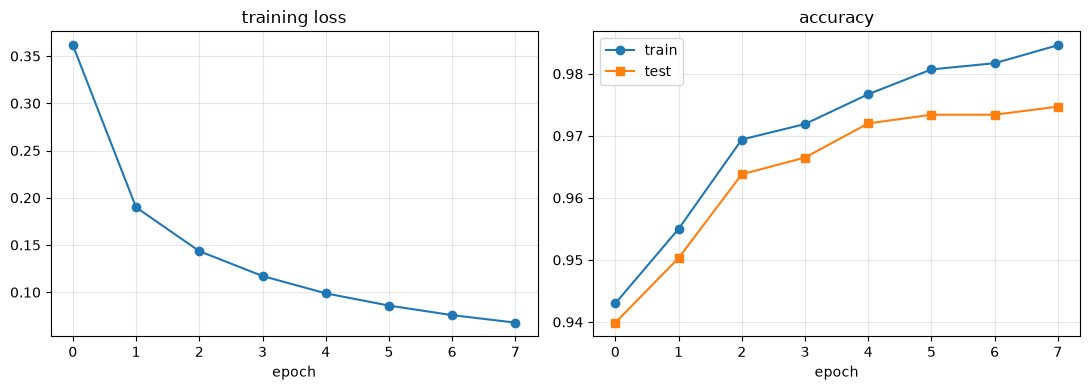

In [100]:
loss_curve = [h[0] for h in hist]
train_curve = [h[1] for h in hist]
test_curve = [h[2] for h in hist]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(loss_curve, marker="o"); ax[0].set_title("training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(train_curve, marker="o", label="train")
ax[1].plot(test_curve, marker="s", label="test")
ax[1].set_title("accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

Around **97%** on images the network has never seen — from about 60 lines of NumPy.

### 4.5 What did it get wrong?

Looking at a model's mistakes is the most useful debugging habit in machine learning.

253 mistakes out of 10000 test images


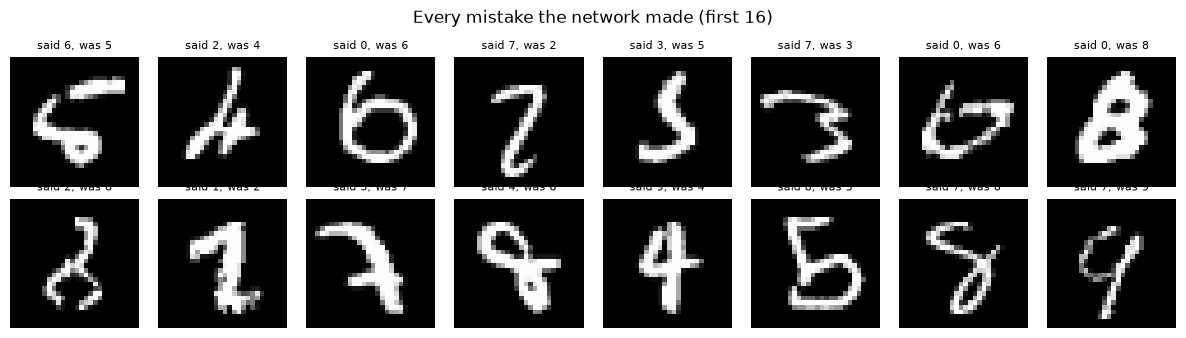

In [101]:
probs = mnist_net.forward(X_test)
preds = probs.argmax(axis=1)
wrong = np.where(preds != y_test)[0]
print(f"{len(wrong)} mistakes out of {len(y_test)} test images")

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, i in zip(axes.ravel(), wrong[:16]):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"said {preds[i]}, was {y_test[i]}", fontsize=8)
    ax.axis("off"); ax.grid(False)
plt.suptitle("Every mistake the network made (first 16)")
plt.tight_layout(); plt.show()

Most of these are genuinely ambiguous — you might have got them wrong too.

### 4.6 What is inside the hidden layer?

Each of the 128 hidden neurons has 784 weights: one per pixel. If we reshape those weights back
into a 28×28 image, we can *see* what pattern that neuron is looking for.
Bright = "I want ink here", dark = "I want no ink here".

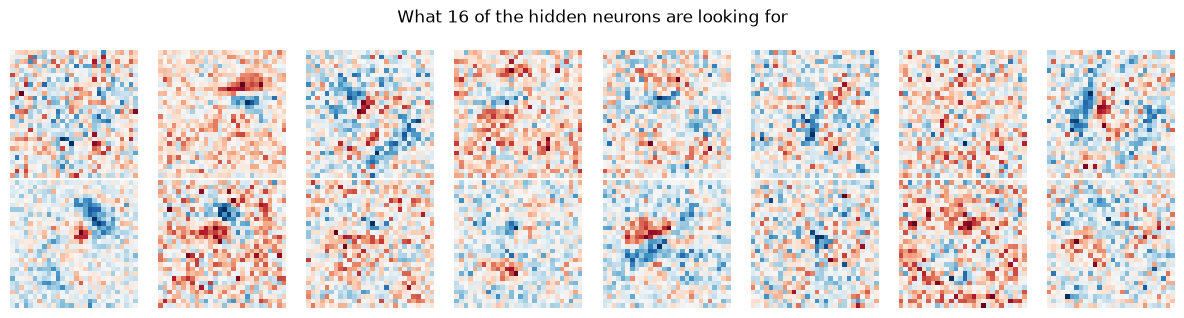

In [102]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(mnist_net.W[0][:, i].reshape(28, 28), cmap="RdBu")
    ax.axis("off"); ax.grid(False)
plt.suptitle("What 16 of the hidden neurons are looking for")
plt.tight_layout(); plt.show()

You can make out strokes, loops and blobs. Nobody programmed those detectors — they emerged
from gradient descent. This is the essence of deep learning: **the features are learned, not
hand-written.**

### 🔧 Your turn #3

Copy the training cell and try:

1. A network with no hidden layer at all: `[784, 10]`. How much accuracy do you lose?
   (This is plain logistic regression — the Part 2 neuron, ten times.)
2. A deeper one: `[784, 256, 64, 10]`. Better or worse? Slower?
3. `lr=1.0` and `lr=0.001`. Watch the loss curve shape change.
4. `batch_size=8` versus `batch_size=512`. Which is faster per epoch? Which learns more per epoch?

In [103]:
# Your turn #3.1 — no hidden layer: [784, 10]
# This is just 10 straight-line classifiers (logistic regression x10), no bend.
import time

no_hidden = NeuralNetwork([784, 10], seed=0)

t0 = time.time()
hist_no_hidden = no_hidden.fit(X_train, y_train, X_test, y_test,
                               epochs=8, batch_size=64, lr=0.1)
print(f"\n[784, 10]  ->  final test acc {hist_no_hidden[-1][2]*100:.2f}%  "
      f"in {time.time()-t0:.1f}s")
print("Compare to the [784, 128, 10] baseline (~97%). The gap = what the hidden layer buys you.")

epoch 1/8   loss 0.4834   train acc 90.63%   test acc 90.86%
epoch 2/8   loss 0.3383   train acc 91.53%   test acc 91.17%
epoch 3/8   loss 0.3152   train acc 91.99%   test acc 91.84%
epoch 4/8   loss 0.3030   train acc 92.22%   test acc 91.89%
epoch 5/8   loss 0.2948   train acc 92.28%   test acc 91.95%
epoch 6/8   loss 0.2894   train acc 92.57%   test acc 92.07%
epoch 7/8   loss 0.2847   train acc 92.45%   test acc 91.92%
epoch 8/8   loss 0.2814   train acc 92.62%   test acc 92.13%

[784, 10]  ->  final test acc 92.13%  in 5.8s
Compare to the [784, 128, 10] baseline (~97%). The gap = what the hidden layer buys you.


In [104]:
# Your turn #3.4 — batch size: 8 vs 512, everything else held fixed
import time

for bs in [8, 512]:
    net = NeuralNetwork([784, 128, 10], seed=0)   # same architecture each time
    t0 = time.time()
    h = net.fit(X_train, y_train, X_test, y_test,
                epochs=8, batch_size=bs, lr=0.1)
    print(f"\nbatch_size={bs:<4} ->  final test acc {h[-1][2]*100:.2f}%  "
          f"in {time.time()-t0:.1f}s\n" + "-"*60)

epoch 1/8   loss 0.2106   train acc 97.27%   test acc 96.83%
epoch 2/8   loss 0.0978   train acc 96.51%   test acc 95.60%
epoch 3/8   loss 0.0703   train acc 98.56%   test acc 97.65%
epoch 4/8   loss 0.0535   train acc 98.62%   test acc 97.28%
epoch 5/8   loss 0.0416   train acc 98.91%   test acc 97.76%
epoch 6/8   loss 0.0339   train acc 98.81%   test acc 97.21%
epoch 7/8   loss 0.0273   train acc 99.37%   test acc 97.81%
epoch 8/8   loss 0.0210   train acc 99.50%   test acc 97.76%

batch_size=8    ->  final test acc 97.76%  in 92.3s
------------------------------------------------------------
epoch 1/8   loss 0.7943   train acc 89.28%   test acc 89.50%
epoch 2/8   loss 0.3775   train acc 91.03%   test acc 90.95%
epoch 3/8   loss 0.3196   train acc 91.85%   test acc 91.72%
epoch 4/8   loss 0.2882   train acc 92.66%   test acc 92.48%
epoch 5/8   loss 0.2644   train acc 93.15%   test acc 93.08%
epoch 6/8   loss 0.2470   train acc 93.64%   test acc 93.34%
epoch 7/8   loss 0.2326   train 

---
# Part 5 — PyTorch: the same ideas, less typing

We now know what a neural network *is*: a stack of matrix multiplications with bends in between,
trained by gradient descent, with gradients computed by the chain rule running backwards.

Writing `backward()` by hand was the point of Parts 1–4. But for real work, nobody does it —
one algebra slip and your network silently learns nothing. Instead we use a library that
computes derivatives automatically. **PyTorch** is the most popular one.

PyTorch gives us exactly three things:

1. **Tensors** — like NumPy arrays, but they can live on a GPU.
2. **Autograd** — it records every operation you perform and can replay it backwards to get
   every gradient. It is doing precisely what we did by hand in Part 3.
3. **Building blocks** — layers, loss functions, and optimisers, pre-written and tested.

In [105]:
import sys
!"{sys.executable}" -m pip install torch

/Users/aayushhegde/Documents/ALL CODING HERE/imitation-learning-grasp/.venv/bin/python: No module named pip


In [106]:
import torch; print(torch.__version__)

2.11.0


In [107]:
import torch
import torch.nn as nn

torch.manual_seed(0)
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available(), "(a CPU is fine for this notebook)")

PyTorch version: 2.11.0
GPU available: False (a CPU is fine for this notebook)


### 5.1 Autograd, on the example we did by hand

Remember section 3.3: $u = 3w$, $v = u^2$, $L = v + 5$, and we worked out $dL/dw = 36$ at $w=2$.
Watch PyTorch get the same answer without being told any calculus.

In [108]:
w = torch.tensor(2.0, requires_grad=True)   # "track the gradient for this one"

u = 3 * w
v = u ** 2
L = v + 5

L.backward()        # walk the chain rule backwards, automatically

print("dL/dw =", w.grad.item(), "   (we derived 36 by hand)")

dL/dw = 36.0    (we derived 36 by hand)


### 5.2 Part 1 all over again, in PyTorch

Same student data, same straight line, same gradient descent — but no hand-derived formulas.
Compare this to the `gradients()` function we wrote in Part 1.

In [109]:
x_t = torch.tensor(hours, dtype=torch.float32)
y_t = torch.tensor(scores, dtype=torch.float32)

w = torch.zeros(1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
optimizer = torch.optim.SGD([w, b], lr=0.01)

for step in range(2000):
    y_hat = w * x_t + b                 # forward
    loss = ((y_hat - y_t) ** 2).mean()  # loss

    optimizer.zero_grad()               # clear last step's gradients
    loss.backward()                     # <-- all of our calculus, in one call
    optimizer.step()                    # w -= lr * w.grad ; b -= lr * b.grad

print(f"PyTorch found:  w = {w.item():.3f},  b = {b.item():.3f}")
print(f"By hand we got: w = {w_final:.3f},  b = {b_final:.3f}")

PyTorch found:  w = 8.444,  b = 29.635
By hand we got: w = 8.444,  b = 29.635


Identical, to three decimals. `loss.backward()` replaced everything we derived in Part 1.

### 5.3 MNIST again, the PyTorch way

Here is the whole Part 4 network as PyTorch would write it. `nn.Sequential` stacks layers;
`nn.Linear(784, 128)` is exactly our `W1` and `b1`.

One difference worth knowing: `nn.CrossEntropyLoss` applies the softmax *itself*, so the
model's final layer outputs raw scores (logits) rather than probabilities.

In [110]:
from torch.utils.data import TensorDataset, DataLoader

def to_loader(X, y, batch_size=64, shuffle=False):
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

train_loader = to_loader(X_train, y_train, batch_size=64, shuffle=True)
test_loader = to_loader(X_test, y_test, batch_size=1000)

model = nn.Sequential(
    nn.Linear(784, 128),   # our W1, b1
    nn.ReLU(),             # our max(0, z)
    nn.Linear(128, 10),    # our W2, b2
)

loss_fn = nn.CrossEntropyLoss()          # softmax + cross-entropy in one object
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

print(model)
n_params = sum(p.numel() for p in model.parameters())
print(f"\n{n_params:,} numbers to learn")

Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=10, bias=True)
)

101,770 numbers to learn


In [111]:
def accuracy_on(model, loader):
    model.eval()
    correct = total = 0
    with torch.no_grad():                      # no gradients needed when testing
        for xb, yb in loader:
            correct += (model(xb).argmax(1) == yb).sum().item()
            total += len(yb)
    return correct / total


def train_torch(model, train_loader, test_loader, epochs=5, lr=0.1, optimizer=None):
    loss_fn = nn.CrossEntropyLoss()
    if optimizer is None:
        optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    history = []

    for epoch in range(epochs):
        model.train()
        running = 0.0
        for xb, yb in train_loader:            # one mini-batch at a time
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)      # forward + loss
            loss.backward()                    # backward
            optimizer.step()                   # update
            running += loss.item()

        test_acc = accuracy_on(model, test_loader)
        train_acc = accuracy_on(model, train_loader)
        history.append((running / len(train_loader), test_acc, train_acc))
        print(f"epoch {epoch + 1}/{epochs}   loss {running / len(train_loader):.4f}"
              f"   train acc {train_acc * 100:5.2f}%   test acc {test_acc * 100:5.2f}%")
    return history

t0 = time.time()
torch_hist = train_torch(model, train_loader, test_loader, epochs=5, lr=0.1)
print(f"\n{time.time() - t0:.1f} seconds")

epoch 1/5   loss 0.4381   train acc 92.14%   test acc 92.50%
epoch 2/5   loss 0.2263   train acc 94.69%   test acc 94.71%
epoch 3/5   loss 0.1700   train acc 95.85%   test acc 95.54%
epoch 4/5   loss 0.1354   train acc 96.81%   test acc 96.46%
epoch 5/5   loss 0.1129   train acc 97.23%   test acc 96.76%

7.4 seconds


The same accuracy as our hand-written network — which is the point. PyTorch is not smarter
than us; it is just less error-prone and much faster on big models.

### 5.4 A better optimiser: Adam

Plain gradient descent takes the same size step in every direction. **Adam** keeps a running
memory of past gradients and gives each weight its own adaptive step size. It usually converges
several times faster, and it's the default choice today.

In [ ]:
model_adam = nn.Sequential(nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
adam_hist = train_torch(model_adam, train_loader, test_loader, epochs=5,
                        optimizer=torch.optim.Adam(model_adam.parameters(), lr=1e-3))

plt.plot([h[1] for h in torch_hist], marker="o", label="SGD, lr=0.1")
plt.plot([h[1] for h in adam_hist], marker="s", label="Adam, lr=0.001")
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.legend()
plt.title("Same network, different optimiser"); plt.show()

---
# Part 6 — A real task: Fashion-MNIST and convolutional networks

MNIST is famously easy. **Fashion-MNIST** has the same format (28×28 grayscale, 10 classes,
70,000 images) but the images are clothing: shirts, coats, sneakers, bags. It is much harder —
and much closer to a real computer-vision problem.

downloading https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/train-images-idx3-ubyte.gz ...
downloading https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/train-labels-idx1-ubyte.gz ...
downloading https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/t10k-images-idx3-ubyte.gz ...
downloading https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/t10k-labels-idx1-ubyte.gz ...


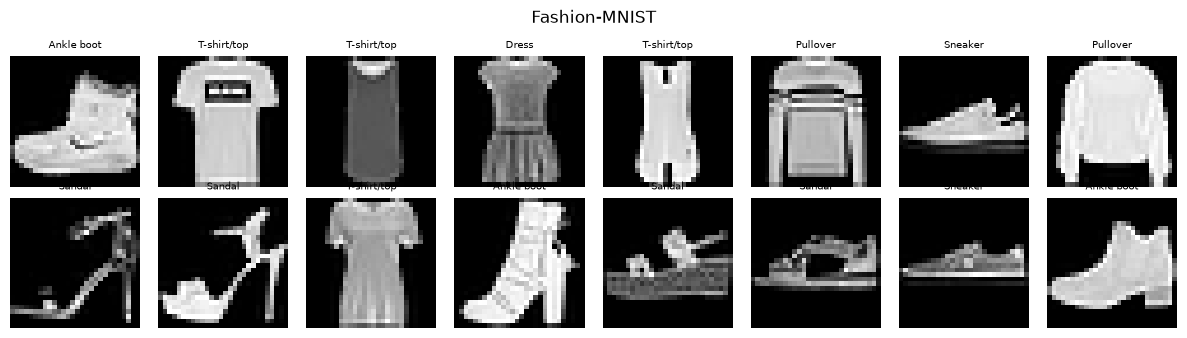

In [112]:
Xf_train, yf_train, Xf_test, yf_test = load_dataset("fashion")

CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(Xf_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(CLASS_NAMES[yf_train[i]], fontsize=7)
    ax.axis("off"); ax.grid(False)
plt.suptitle("Fashion-MNIST")
plt.tight_layout(); plt.show()

### 6.1 Baseline: the network we already have

Always build the simplest thing first, so you know whether the fancy thing was worth it.

In [113]:
f_train_loader = to_loader(Xf_train, yf_train, batch_size=128, shuffle=True)
f_test_loader = to_loader(Xf_test, yf_test, batch_size=1000)

mlp = nn.Sequential(
    nn.Linear(784, 256), nn.ReLU(),
    nn.Linear(256, 128), nn.ReLU(),
    nn.Linear(128, 10),
)

t0 = time.time()
mlp_hist = train_torch(mlp, f_train_loader, f_test_loader, epochs=6,
                       optimizer=torch.optim.Adam(mlp.parameters(), lr=1e-3))
mlp_time = time.time() - t0
mlp_acc = mlp_hist[-1][1]
print(f"\nbaseline: {mlp_acc * 100:.2f}% in {mlp_time:.0f}s")

epoch 1/6   loss 0.5673   train acc 84.22%   test acc 82.89%
epoch 2/6   loss 0.3867   train acc 86.90%   test acc 85.35%
epoch 3/6   loss 0.3441   train acc 88.75%   test acc 87.08%
epoch 4/6   loss 0.3186   train acc 88.87%   test acc 86.84%
epoch 5/6   loss 0.3011   train acc 89.60%   test acc 87.22%
epoch 6/6   loss 0.2842   train acc 90.43%   test acc 88.15%

baseline: 88.15% in 15s


Around **88%**. Notice it is stuck far below MNIST's 97%. To do better we need to fix
something our network has been doing wrong from the very beginning.

### 6.2 The problem with flattening

We turned each 28×28 image into a list of 784 numbers. That throws away the fact that
**pixel 100 and pixel 101 are neighbours**. To our network, an image is a bag of 784
unrelated measurements — shuffle the pixel order (the same way for every image) and it would
learn just as well. That is clearly not how seeing works.

Two more problems:

- A sleeve in the top-left and the same sleeve in the bottom-right need *completely separate*
  weights to be learned.
- `nn.Linear(784, 256)` has 200,704 weights. That's a lot of numbers to learn from 60,000 images.

### 6.3 Convolution

A **convolution** slides a small window — a **kernel**, typically 3×3 — across the image.
At each position it computes a weighted sum of those 9 pixels:

$$\text{output}(i,j) = \sum_{u=-1}^{1}\sum_{v=-1}^{1} K(u,v)\cdot \text{image}(i+u,\, j+v)$$

The same 9 weights are used at every position. This gives us three wins:

- **locality** — it looks at neighbourhoods, so spatial structure survives;
- **weight sharing** — an edge detector learned in one corner works everywhere, and the layer
  has only 9 weights instead of hundreds of thousands;
- **translation tolerance** — a sneaker is recognised wherever it appears.

Here is a hand-designed kernel that detects vertical edges, so you can see it work before we
let the network learn its own.

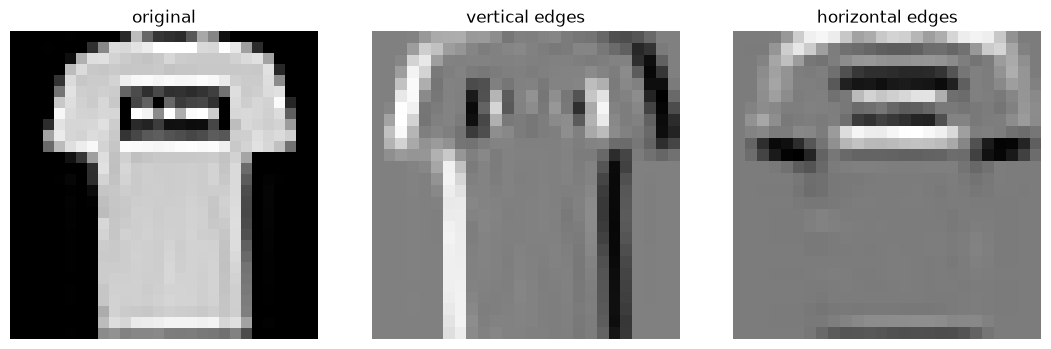

In [114]:
def convolve2d(image, kernel):
    # The simplest possible convolution: slide the kernel over the image.
    kh, kw = kernel.shape
    h, w = image.shape
    out = np.zeros((h - kh + 1, w - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            patch = image[i:i + kh, j:j + kw]
            out[i, j] = np.sum(patch * kernel)
    return out

img = Xf_train[1].reshape(28, 28)          # a trouser image
vertical_edges = np.array([[-1, 0, 1],
                           [-2, 0, 2],
                           [-1, 0, 1]], dtype=float)   # the Sobel filter
horizontal_edges = vertical_edges.T

fig, ax = plt.subplots(1, 3, figsize=(11, 3.5))
for a, (im, title) in zip(ax, [(img, "original"),
                               (convolve2d(img, vertical_edges), "vertical edges"),
                               (convolve2d(img, horizontal_edges), "horizontal edges")]):
    a.imshow(im, cmap="gray"); a.set_title(title); a.axis("off"); a.grid(False)
plt.tight_layout(); plt.show()

Nine numbers found all the vertical edges in the image. In a **convolutional neural network (CNN)**
we don't design those nine numbers — they are weights, learned by exactly the same gradient
descent we've used since Part 1.

### 6.4 A small CNN

Our architecture:

```
28x28x1  --conv 3x3, 16 filters--> 28x28x16 --ReLU--> --maxpool 2x2--> 14x14x16
         --conv 3x3, 32 filters--> 14x14x32 --ReLU--> --maxpool 2x2-->  7x7x32
         --flatten--> 1568 --Linear--> 128 --ReLU--> --Linear--> 10
```

**Max pooling** keeps only the largest value in each 2×2 square. It halves the size (making
everything faster) and adds a little tolerance to shifting: "there was a strong edge somewhere
around here" matters more than its exact pixel.

The convolutional layers do the *seeing*; the linear layers at the end do the *deciding*.

In [115]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),   # 1 channel in, 16 filters out
            nn.ReLU(),
            nn.MaxPool2d(2),                              # 28x28 -> 14x14
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                              # 14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(0.25),        # randomly switch off 25% of neurons while training,
                                     # which discourages the net from memorising
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = x.view(-1, 1, 28, 28)    # un-flatten: the CNN wants a real 2D image
        return self.classifier(self.features(x))

cnn = SmallCNN()
print(cnn)
print(f"\n{sum(p.numel() for p in cnn.parameters()):,} parameters "
      f"(the flat network had {sum(p.numel() for p in mlp.parameters()):,})")

SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

206,922 parameters (the flat network had 235,146)


In [116]:
# This is the slowest cell in the notebook: expect roughly 1-2 minutes per epoch
# on a laptop CPU (much less on a GPU). Reduce EPOCHS to 3 if you're impatient.
EPOCHS = 6

t0 = time.time()
cnn_hist = train_torch(cnn, f_train_loader, f_test_loader, epochs=EPOCHS,
                       optimizer=torch.optim.Adam(cnn.parameters(), lr=1e-3))
cnn_time = time.time() - t0
cnn_acc = cnn_hist[-1][1]
print(f"\nCNN: {cnn_acc * 100:.2f}% in {cnn_time:.0f}s")
print(f"MLP: {mlp_acc * 100:.2f}% in {mlp_time:.0f}s")

epoch 1/6   loss 0.6431   train acc 85.16%   test acc 84.41%
epoch 2/6   loss 0.3952   train acc 88.55%   test acc 87.53%
epoch 3/6   loss 0.3369   train acc 89.42%   test acc 88.14%
epoch 4/6   loss 0.3049   train acc 90.62%   test acc 89.14%
epoch 5/6   loss 0.2824   train acc 90.75%   test acc 88.95%
epoch 6/6   loss 0.2662   train acc 91.49%   test acc 89.60%

CNN: 89.60% in 181s
MLP: 88.15% in 15s


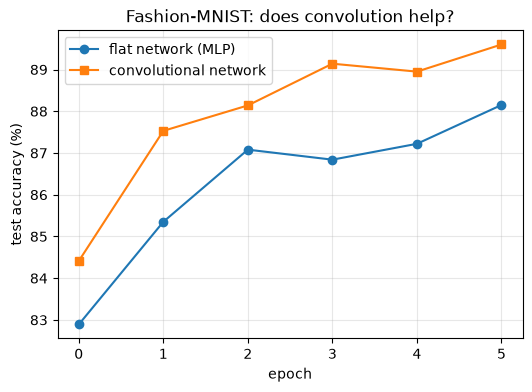

In [117]:
plt.plot([h[1] * 100 for h in mlp_hist], marker="o", label="flat network (MLP)")
plt.plot([h[1] * 100 for h in cnn_hist], marker="s", label="convolutional network")
plt.xlabel("epoch"); plt.ylabel("test accuracy (%)")
plt.legend(); plt.title("Fashion-MNIST: does convolution help?")
plt.show()

The CNN wins by roughly **two percentage points** while using *fewer* parameters — and it was
still improving when we stopped. Two points may sound small, but it is a 15–20% reduction in
the number of mistakes, and the gap grows with more epochs, more data, and bigger images.
On full-size colour photographs the difference between flat and convolutional networks is not
two points; it is the difference between useless and useful.

### 6.5 Reading the results properly

Accuracy is a single number, and single numbers hide things. A **confusion matrix** shows
*which* classes get mixed up with which.

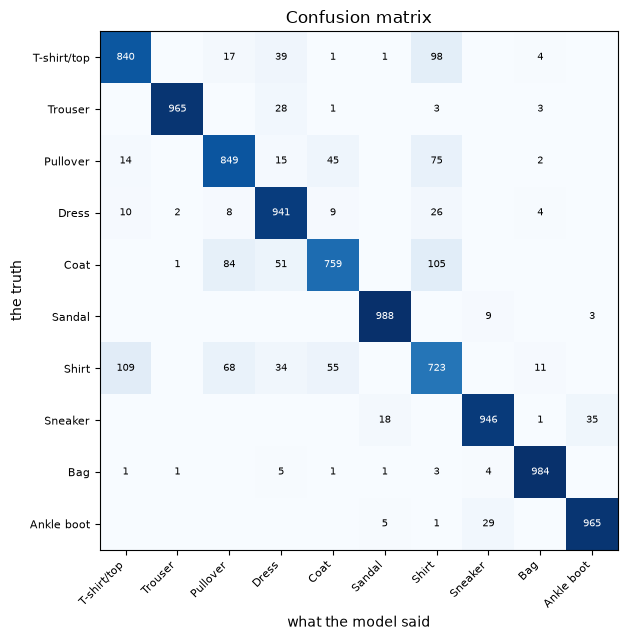

Shirt         72.3%
Coat          75.9%
T-shirt/top   84.0%
Pullover      84.9%
Dress         94.1%
Sneaker       94.6%
Trouser       96.5%
Ankle boot    96.5%
Bag           98.4%
Sandal        98.8%


In [118]:
cnn.eval()
all_preds = []
with torch.no_grad():
    for xb, yb in f_test_loader:
        all_preds.append(cnn(xb).argmax(1).numpy())
all_preds = np.concatenate(all_preds)

confusion = np.zeros((10, 10), dtype=int)
for true, pred in zip(yf_test, all_preds):
    confusion[true, pred] += 1

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(confusion, cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES, fontsize=8)
ax.set_xlabel("what the model said"); ax.set_ylabel("the truth")
ax.grid(False)
for i in range(10):
    for j in range(10):
        if confusion[i, j] > 0:
            ax.text(j, i, confusion[i, j], ha="center", va="center", fontsize=7,
                    color="white" if confusion[i, j] > confusion.max() / 2 else "black")
plt.title("Confusion matrix"); plt.tight_layout(); plt.show()

per_class = confusion.diagonal() / confusion.sum(axis=1)
for name, acc in sorted(zip(CLASS_NAMES, per_class), key=lambda t: t[1]):
    print(f"{name:12} {acc * 100:5.1f}%")

The bottom of that list is almost always **Shirt**, confused with T-shirt, Pullover and Coat.
That is not a bug in our network — in a 28×28 grayscale image those four things genuinely
look alike. Knowing *where* your model's errors come from tells you what to do next
(here: higher-resolution images or colour would help far more than a bigger network).

### 6.6 What the CNN learned to look for

The first convolutional layer has 16 kernels of 3×3. Let's look at them, and at what they
do to a real image.

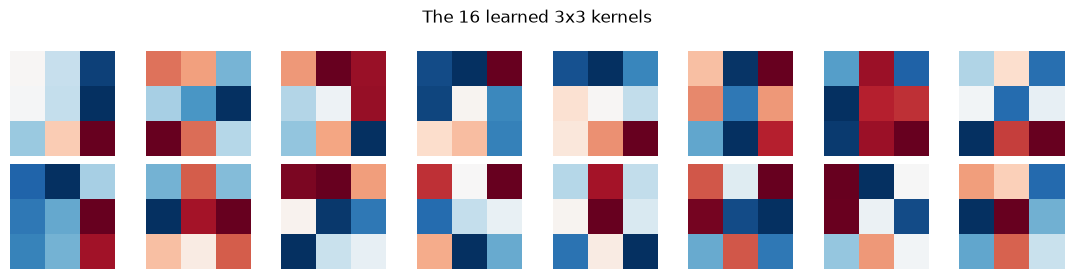

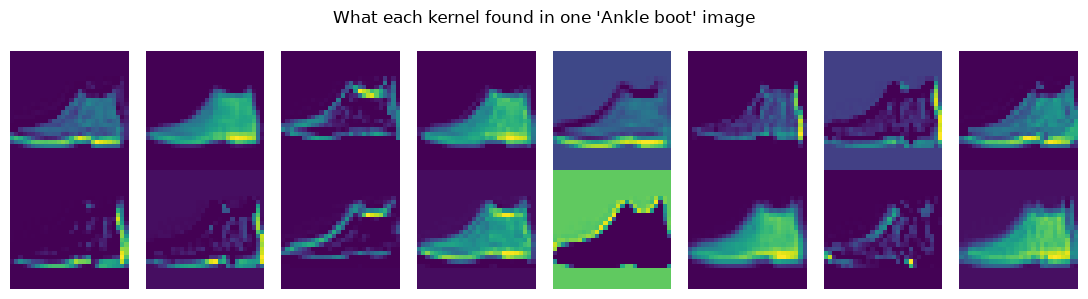

In [119]:
kernels = cnn.features[0].weight.detach().numpy()   # shape (16, 1, 3, 3)

fig, axes = plt.subplots(2, 8, figsize=(11, 2.8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(kernels[i, 0], cmap="RdBu"); ax.axis("off"); ax.grid(False)
plt.suptitle("The 16 learned 3x3 kernels"); plt.tight_layout(); plt.show()

sample = torch.tensor(Xf_test[0], dtype=torch.float32).view(1, 1, 28, 28)
with torch.no_grad():
    feature_maps = torch.relu(cnn.features[0](sample))[0].numpy()

fig, axes = plt.subplots(2, 8, figsize=(11, 3))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(feature_maps[i], cmap="viridis"); ax.axis("off"); ax.grid(False)
plt.suptitle(f"What each kernel found in one '{CLASS_NAMES[yf_test[0]]}' image")
plt.tight_layout(); plt.show()

### 6.7 Overfitting — the thing that will bite you

If you train long enough, training accuracy keeps climbing while test accuracy stalls or drops.
The network has started **memorising** the training images instead of learning what a sneaker is.

The standard defences:

| Trick | What it does |
|---|---|
| More data | The most reliable fix, always |
| **Dropout** | Randomly switch off neurons while training (we used 25% above) |
| Data augmentation | Flip / shift / rotate training images to invent new examples |
| Early stopping | Stop when test accuracy stops improving |
| Weight decay | Penalise large weights, keeping the model simple |

We recorded training accuracy as well as test accuracy, so we can watch the gap open up:

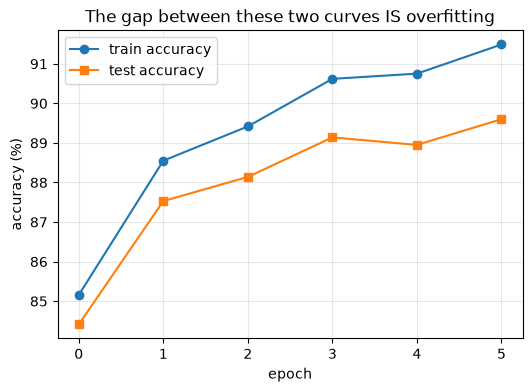

final gap: 1.89 percentage points
A small gap is normal. A large and growing gap means the network is memorising.


In [120]:
plt.plot([h[2] * 100 for h in cnn_hist], marker="o", label="train accuracy")
plt.plot([h[1] * 100 for h in cnn_hist], marker="s", label="test accuracy")
plt.xlabel("epoch"); plt.ylabel("accuracy (%)"); plt.legend()
plt.title("The gap between these two curves IS overfitting")
plt.show()

gap = (cnn_hist[-1][2] - cnn_hist[-1][1]) * 100
print(f"final gap: {gap:.2f} percentage points")
print("A small gap is normal. A large and growing gap means the network is memorising.")

### 🔧 Your turn #4

1. Delete the `nn.Dropout(0.25)` line, retrain, and compare the gap between train and test accuracy.
2. Add a third conv block (`Conv2d(32, 64, 3, padding=1)` + ReLU + MaxPool → the flatten size
   becomes `64 * 3 * 3`). Does it help?
3. Train for 15 epochs and plot train vs test accuracy on the same axes. Can you *see* overfitting begin?
4. Try `lr=0.01` with Adam. What happens? (Adam is much fussier about learning rate than you'd hope.)

---
# Part 7 — What you now know, and where to go next

### The whole notebook in nine lines

1. A neuron computes a weighted sum of its inputs, plus a bias.
2. An activation function bends that output, so that stacked layers can do more than one line.
3. A loss function measures how wrong the network is, as a single number.
4. The gradient of the loss says which way is downhill for every weight.
5. Gradient descent takes a small step downhill, over and over.
6. Backpropagation computes all those gradients efficiently with the chain rule, backwards.
7. Softmax + cross-entropy turn a network into a classifier, and their gradient is
   *prediction minus truth* — the same pattern as every other layer.
8. Convolutions exploit the fact that images have neighbourhoods, using far fewer weights.
9. Everything else in modern AI is a variation on these nine lines.

That last point is not an exaggeration. The model you're reading this from is a transformer:
billions of parameters, a different way of mixing information between positions — but still
matrix multiplications with bends, a loss function, and gradient descent driven by
backpropagation. You now know the machinery.

### Good next steps

- **Play** — [playground.tensorflow.org](https://playground.tensorflow.org) lets you drag layers
  around and watch decision boundaries form in real time. Ten minutes there is worth an hour of reading.
- **Watch** — 3Blue1Brown's *Neural Networks* series is the best visual explanation of
  backpropagation ever made.
- **Read** — Michael Nielsen's free book *Neural Networks and Deep Learning* covers Parts 1–4
  in far more depth.
- **Build** — try CIFAR-10 (colour photos, 10 classes), or feed the network your *own*
  handwriting: draw a digit in any paint program, save it 28×28, invert it so the digit is
  white on black, and see whether the MNIST model recognises it.
- **Learn the vocabulary** — batch normalisation, residual connections, transformers, attention.
  Each is one more idea bolted onto the frame you just built.

### A last thought

Everything in this notebook — sigmoid neurons, backprop, convolution — was invented between
1958 and 1998. What changed after 2012 was not the mathematics but the amount of data and
the arrival of GPUs. The ideas were waiting.

---
## Solutions to the 🔧 exercises

**#1 — Learning rate.**
`lr=0.001` works but crawls: after 2000 steps the loss is still around 38, versus about 8.3 for
`lr=0.01`. `lr=0.03` gets there faster. `lr=0.05` **diverges** — each step overshoots the valley
and lands further up the other side, so the loss grows until Python reports an overflow and
prints `inf` or `nan`.
The safe learning rate depends on the scale of your data; this is exactly why practitioners
normalise inputs to roughly the range 0–1, as we did with MNIST pixels.

**#2 — Hidden units and activations.**
- `HIDDEN=1`: about 50–75%. One hidden neuron gives one bend, and XOR needs two.
- `ACTIVATION="identity"` with 16 hidden units: still ~50%, and the boundary is a
  **straight line**. Composing linear maps gives a linear map — the extra layer is
  mathematically wasted. This is the single most important reason activation functions exist.
- `LR=5.0`: usually still learns (this problem is forgiving) but the loss curve becomes jagged,
  and with some seeds it gets stuck. Bigger models break much sooner.

**#3 — MNIST architectures.**
- `[784, 10]` (no hidden layer): about 92%. Perfectly decent — and a good reminder that
  most of the easy accuracy comes from the simplest model. The remaining 5% is what the
  hidden layer buys you.
- `[784, 256, 64, 10]`: roughly the same as one hidden layer, maybe a touch better, and slower.
  Fully-connected depth stops paying off quickly; convolution is what actually helps on images.
- `lr=1.0`: the loss curve jumps around and may plateau high. `lr=0.001`: smooth but far too slow.
- `batch_size=8` learns more per epoch (more updates) but each epoch takes longer;
  `batch_size=512` is fast per epoch but needs a bigger learning rate to keep up.

**#4 — CNN experiments.**
- Removing dropout: training accuracy climbs faster and higher, test accuracy doesn't —
  the *gap* between them widens. That gap is overfitting, made visible.
- A third conv block usually gains a little (~0.5–1%), and costs training time. Beyond that,
  the limit is the data, not the model.
- At 15 epochs the train/test curves visibly separate.
- `lr=0.01` with Adam is typically too large here: the loss jumps around and the final accuracy
  is worse. Adam's usual home is `1e-3` to `1e-4`.